In [1]:
# Cell 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Cell 3: Load the CSV File into a DataFrame

df = pd.read_csv("Telecom_Tower_Failure_Dataset.csv")

# Display the first five rows
df.head()

,Tower_ID,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs
0,1,35.6,50.91,2962,56,2838,52,2612,4,0
1,2,43.9,53.33,736,69,3139,36,3427,6,0
2,3,29.0,51.01,2335,50,3117,81,4254,11,1
3,4,39.0,45.62,2808,88,3367,92,1575,7,0
4,5,56.8,51.29,2590,100,1040,25,1336,4,1


In [4]:
# Cell 4: Check the Number of Rows and Columns

print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (10000, 10)
Number of records: 10000
Number of columns: 10


In [5]:
# Cell 5: Display All Column Names

print(df.columns.tolist())

['Tower_ID', 'Temperature_C', 'Battery_Voltage', 'Power_Consumption_W', 'Signal_Strength_Percent', 'Fan_Speed_RPM', 'Humidity_Percent', 'Traffic_Load', 'Tower_Age_Years', 'Failure_Within_48Hrs']


In [6]:
# Cell 6: Check Column Data Types and Non-Null Values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Tower_ID                 10000 non-null  int64  
 1   Temperature_C            10000 non-null  float64
 2   Battery_Voltage          10000 non-null  float64
 3   Power_Consumption_W      10000 non-null  int64  
 4   Signal_Strength_Percent  10000 non-null  int64  
 5   Fan_Speed_RPM            10000 non-null  int64  
 6   Humidity_Percent         10000 non-null  int64  
 7   Traffic_Load             10000 non-null  int64  
 8   Tower_Age_Years          10000 non-null  int64  
 9   Failure_Within_48Hrs     10000 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 781.4 KB


In [7]:
# Cell 7: Display Descriptive Statistics

df.describe()

,Tower_ID,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,44.832100,48.024044,1750.302400,69.889500,2156.190700,57.399500,2557.349500,8.021600,0.661300
std,2886.89568,14.529069,3.500936,719.566051,17.706028,785.127883,21.858318,1420.845085,4.309825,0.473291
min,1.00000,20.000000,42.000000,500.000000,40.000000,800.000000,20.000000,100.000000,1.000000,0.000000
25%,2500.75000,32.300000,44.970000,1123.000000,54.000000,1464.000000,38.000000,1310.000000,4.000000,0.000000
50%,5000.50000,44.700000,48.050000,1753.500000,70.000000,2154.000000,57.000000,2563.000000,8.000000,1.000000
75%,7500.25000,57.600000,51.070000,2368.000000,85.000000,2839.000000,76.000000,3785.000000,12.000000,1.000000
max,10000.00000,70.000000,54.000000,3000.000000,100.000000,3500.000000,95.000000,5000.000000,15.000000,1.000000


In [8]:
# Cell 8: Count Missing Values in Each Column

print(df.isnull().sum())

Tower_ID                   0
Temperature_C              0
Battery_Voltage            0
Power_Consumption_W        0
Signal_Strength_Percent    0
Fan_Speed_RPM              0
Humidity_Percent           0
Traffic_Load               0
Tower_Age_Years            0
Failure_Within_48Hrs       0
dtype: int64


In [9]:
# Cell 9: Fill Missing Numerical Values with Their Median

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Check Missing Values Again
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Tower_ID                   0
Temperature_C              0
Battery_Voltage            0
Power_Consumption_W        0
Signal_Strength_Percent    0
Fan_Speed_RPM              0
Humidity_Percent           0
Traffic_Load               0
Tower_Age_Years            0
Failure_Within_48Hrs       0
dtype: int64


In [10]:
# Cell 10: Create a Binary Feature for High Temperature

df["High_Temperature"] = np.where(
    df["Temperature_C"] > 60,
    1,
    0
)

# Display the Original and New Columns
df[["Temperature_C", "High_Temperature"]].head()

,Temperature_C,High_Temperature
0,35.6,0
1,43.9,0
2,29.0,0
3,39.0,0
4,56.8,0


In [11]:
# Cell 11: Create a Binary Feature for Low Battery

df["Low_Battery"] = np.where(
    df["Battery_Voltage"] < 45,
    1,
    0
)

# Display the Original and New Columns
df[["Battery_Voltage", "Low_Battery"]].head()

,Battery_Voltage,Low_Battery
0,50.91,0
1,53.33,0
2,51.01,0
3,45.62,0
4,51.29,0


In [12]:
# Cell 12: Calculate the Power-Traffic Ratio

df["Power_Traffic_Ratio"] = (
    df["Power_Consumption_W"] /
    (df["Traffic_Load"] + 0.01)
)

# Display the Original and New Columns
df[
    [
        "Power_Consumption_W",
        "Traffic_Load",
        "Power_Traffic_Ratio"
    ]
].head()

,Power_Consumption_W,Traffic_Load,Power_Traffic_Ratio
0,2962,2612,1.133993
1,736,3427,0.214764
2,2335,4254,0.548894
3,2808,1575,1.782846
4,2590,1336,1.938608


In [13]:
# Cell 13: Convert Tower Age into Categories

df["Tower_Age_Category"] = pd.cut(
    df["Tower_Age_Years"],
    bins=[-np.inf, 3, 7, np.inf],
    labels=["New", "Medium", "Old"],
    right=True
)

# Display the Original and New Columns
df[
    ["Tower_Age_Years", "Tower_Age_Category"]
].head()

,Tower_Age_Years,Tower_Age_Category
0,4,Medium
1,6,Medium
2,11,Old
3,7,Medium
4,4,Medium


In [14]:
# Cell 14: Convert Tower Age Categories into Numerical Columns

df = pd.get_dummies(
    df,
    columns=["Tower_Age_Category"],
    dtype=int
)

# Display the Updated Dataset
df.head()

,Tower_ID,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,1,35.6,50.91,2962,56,2838,52,2612,4,0,0,0,1.133993,0,1,0
1,2,43.9,53.33,736,69,3139,36,3427,6,0,0,0,0.214764,0,1,0
2,3,29.0,51.01,2335,50,3117,81,4254,11,1,0,0,0.548894,0,0,1
3,4,39.0,45.62,2808,88,3367,92,1575,7,0,0,0,1.782846,0,1,0
4,5,56.8,51.29,2590,100,1040,25,1336,4,1,0,0,1.938608,0,1,0


In [15]:
# Cell 15: Remove the Identifier Column

df = df.drop(
    columns=["Tower_ID"]
)

# Display the Updated Dataset
df.head()

,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,35.6,50.91,2962,56,2838,52,2612,4,0,0,0,1.133993,0,1,0
1,43.9,53.33,736,69,3139,36,3427,6,0,0,0,0.214764,0,1,0
2,29.0,51.01,2335,50,3117,81,4254,11,1,0,0,0.548894,0,0,1
3,39.0,45.62,2808,88,3367,92,1575,7,0,0,0,1.782846,0,1,0
4,56.8,51.29,2590,100,1040,25,1336,4,1,0,0,1.938608,0,1,0


In [16]:
# Cell 16: Separate Input Features (X) and Target (y)

X = df.drop(
    columns=["Failure_Within_48Hrs"]
)

y = df["Failure_Within_48Hrs"]

# Display the First Five Rows of X and y
print("Input Features (X):")
display(X.head())

print("Target (y):")
display(y.head())

Input Features (X):


,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,35.6,50.91,2962,56,2838,52,2612,4,0,0,1.133993,0,1,0
1,43.9,53.33,736,69,3139,36,3427,6,0,0,0.214764,0,1,0
2,29.0,51.01,2335,50,3117,81,4254,11,0,0,0.548894,0,0,1
3,39.0,45.62,2808,88,3367,92,1575,7,0,0,1.782846,0,1,0
4,56.8,51.29,2590,100,1040,25,1336,4,0,0,1.938608,0,1,0


Target (y):


,Failure_Within_48Hrs
0,0
1,0
2,1
3,0
4,1


In [17]:
# Cell 17: Check the Number of Features and Records

print("Number of features:", X.shape[1])
print("Number of records in X:", X.shape[0])
print("Number of records in y:", y.shape[0])

Number of features: 14
Number of records in X: 10000
Number of records in y: 10000


Target distribution:
Failure_Within_48Hrs
1    6613
0    3387
Name: count, dtype: int64


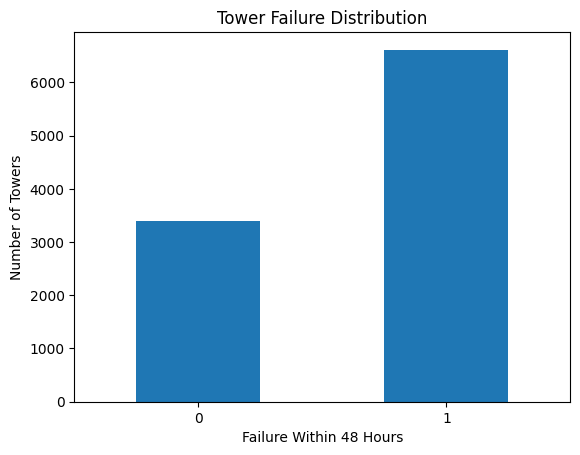

In [18]:
# Cell 18: Count the Target Classes

print("Target distribution:")
print(y.value_counts())

# Plot the Target Distribution
y.value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Failure Within 48 Hours")
plt.ylabel("Number of Towers")
plt.title("Tower Failure Distribution")
plt.xticks(rotation=0)
plt.show()

In [19]:
# Cell 19: Save the Processed Dataset as a CSV File

df.to_csv(
    "telecom_tower_feature_engineered.csv",
    index=False
)

print("Processed dataset saved successfully!")

# Display the First Five Rows
df.head()

Processed dataset saved successfully!


,Temperature_C,Battery_Voltage,Power_Consumption_W,Signal_Strength_Percent,Fan_Speed_RPM,Humidity_Percent,Traffic_Load,Tower_Age_Years,Failure_Within_48Hrs,High_Temperature,Low_Battery,Power_Traffic_Ratio,Tower_Age_Category_New,Tower_Age_Category_Medium,Tower_Age_Category_Old
0,35.6,50.91,2962,56,2838,52,2612,4,0,0,0,1.133993,0,1,0
1,43.9,53.33,736,69,3139,36,3427,6,0,0,0,0.214764,0,1,0
2,29.0,51.01,2335,50,3117,81,4254,11,1,0,0,0.548894,0,0,1
3,39.0,45.62,2808,88,3367,92,1575,7,0,0,0,1.782846,0,1,0
4,56.8,51.29,2590,100,1040,25,1336,4,1,0,0,1.938608,0,1,0


In [21]:
# Cell 20: Download the Processed CSV File

from google.colab import files

files.download("telecom_tower_feature_engineered.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>